# Aprendizagem Supervisionada Aplicada

## IPV/ESTGL 2025/2026
## Mestrado em Controlo de Gestão e Ciência de Dados

##### Professor: Ricardo Gama 
##### Trabalho realizado por: Hélder Vieira 23678

## Análise e Previsão de Atrasos em Voos Comerciais com Recurso a Algoritmos de Regressão

### Enquadramento inicial

O setor da aviação comercial desempenha um papel fundamental na mobilidade global de pessoas e mercadorias. A crescente complexidade das operações aeroportuárias e o elevado número de voos realizados diariamente tornam a gestão da pontualidade um desafio constante para companhias aéreas e aeroportos.

Os atrasos nos voos podem resultar de diversos fatores, como condições meteorológicas adversas, congestionamento do tráfego aéreo, problemas operacionais ou limitações de infraestrutura. Estes atrasos têm impacto direto na experiência dos passageiros e geram custos adicionais para as companhias aéreas.

Com o crescimento da disponibilidade de dados operacionais, as técnicas de Machine Learning têm vindo a ser utilizadas para identificar padrões e apoiar a previsão de eventos futuros. Neste contexto, a previsão de atrasos em voos constitui um problema relevante, permitindo antecipar situações de risco e melhorar o planeamento operacional.

O presente trabalho utiliza um conjunto de dados de voos domésticos dos Estados Unidos da América, contendo informação sobre companhias aéreas, aeroportos, horários de partida e chegada, distâncias percorridas e atrasos registados. O objetivo consiste em desenvolver um modelo de classificação capaz de prever a ocorrência de atrasos significativos nos voos com base nas características disponíveis antes da partida.

### Definição do problema

O objetivo deste trabalho consiste em desenvolver modelos de aprendizagem supervisionada capazes de analisar e prever atrasos em voos comerciais, utilizando informação disponível antes da realização do voo.

Numa primeira abordagem, o problema foi enquadrado como uma tarefa de classificação binária, distinguindo voos sem atraso significativo de voos atrasados. Para esse efeito, considerou-se como atraso significativo qualquer voo com atraso superior a 15 minutos na chegada.

Posteriormente, o problema foi reformulado como uma tarefa de regressão, com o objetivo de prever diretamente o valor do atraso à chegada (`ARRIVAL_DELAY`), expresso em minutos. Esta abordagem permite obter uma estimativa mais detalhada da magnitude do atraso, em vez de apenas classificar o voo como atrasado ou não atrasado.

A referência aos 15 minutos mantém-se relevante como critério operacional para interpretar os resultados, uma vez que atrasos superiores a este limite tendem a ter maior impacto para passageiros, companhias aéreas e operações aeroportuárias.

A previsão será efetuada com base em variáveis como a companhia aérea, aeroportos de origem e destino, horários programados, distância do voo e outras características disponíveis no conjunto de dados.

Desta forma, pretende-se responder à seguinte questão de investigação:

- É possível prever a magnitude do atraso de chegada de voos comerciais utilizando informação disponível antes da partida?

Para responder a esta questão serão desenvolvidos e avaliados diferentes modelos de regressão, comparando o seu desempenho através de métricas adequadas, como MAE, MSE, RMSE e R², e analisando os fatores que mais contribuem para a ocorrência e intensidade dos atrasos.

### Objetivos do trabalho

Os principais objetivos deste trabalho são:

- Analisar e compreender a estrutura do conjunto de dados, identificando as variáveis mais relevantes para o problema em estudo;
- Realizar uma análise exploratória dos dados, de modo a identificar padrões, tendências e possíveis relações entre as variáveis;
- Efetuar o pré-processamento dos dados, incluindo tratamento de valores em falta, seleção de atributos e transformação de variáveis categóricas;
- Construir uma variável alvo que permita classificar os voos em atrasados e não atrasados;
- Desenvolver e treinar diferentes modelos de classificação supervisionada;
- Avaliar e comparar o desempenho dos modelos através de métricas adequadas para problemas de classificação;
- Identificar os fatores com maior influência na ocorrência de atrasos;
-Determinar qual o modelo mais adequado para a previsão de atrasos no contexto do conjunto de dados analisado.

### Origem e acesso aos dados

Os dados utilizados neste trabalho foram obtidos através da plataforma Kaggle, a partir do conjunto de dados Flight Delays, disponibilizado com base em informação recolhida pelo Departamento de Transportes dos Estados Unidos (U.S. Department of Transportation).

O conjunto de dados encontra-se disponível publicamente no endereço:

https://www.kaggle.com/datasets/usdot/flight-delays/data

Este dataset contém informação relativa a voos domésticos realizados nos Estados Unidos durante o ano de 2015, incluindo dados sobre companhias aéreas, aeroportos de origem e destino, horários programados e efetivos de partida e chegada, distâncias percorridas e diferentes tipos de atrasos.

Para a realização deste trabalho foram utilizados os seguintes ficheiros:

- flights.csv – contém os registos dos voos e as respetivas características operacionais;
- airlines.csv – contém informação sobre as companhias aéreas presentes nos registos;
- airports.csv – contém informação relativa aos aeroportos de origem e destino.

O ficheiro principal utilizado na análise é o flights.csv, sendo os restantes ficheiros utilizados como complemento para a identificação e interpretação de algumas variáveis. A integração destes dados permite uma análise mais completa dos fatores associados à ocorrência de atrasos nos voos comerciais.

Os dados foram importados para o ambiente Python utilizando a biblioteca Pandas, sendo posteriormente submetidos a um processo de exploração, limpeza e preparação para aplicação de técnicas de aprendizagem supervisionada.

### Importação das bibliotecas

In [2]:
# Manipulação de dados
import pandas as pd
import numpy as np

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações gráficas
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Pré-processamento
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Modelos de Classificação
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Métricas de Avaliação
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Ignorar avisos
import warnings
# warnings.filterwarnings("ignore")

In [3]:
flights = pd.read_csv("data/flights.csv")
airlines = pd.read_csv("data/airlines.csv")
airports = pd.read_csv("data/airports.csv")

C:\Users\Daniel\AppData\Local\Temp\ipykernel_7976\3369490694.py:1: DtypeWarning: Columns (7,8) have mixed types. Specify dtype option on import or set low_memory=False.
  flights = pd.read_csv("data/flights.csv")


In [3]:
flights.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
airlines.head()

,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.
3,F9,Frontier Airlines Inc.
4,B6,JetBlue Airways


In [5]:
airports.head()

,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65236,-75.44040
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41132,-99.68190
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04022,-106.60919
3,ABR,Aberdeen Regional Airport,Aberdeen,SD,USA,45.44906,-98.42183
4,ABY,Southwest Georgia Regional Airport,Albany,GA,USA,31.53552,-84.19447


#### Dimensão do Dataset

In [6]:
print("Flights - Número de linhas e colunas:", flights.shape)
print("Airlines - Número de linhas e colunas:", airlines.shape)
print("Airports - Número de linhas e colunas:", airports.shape)

Flights - Número de linhas e colunas: (5819079, 31)
Airlines - Número de linhas e colunas: (14, 2)
Airports - Número de linhas e colunas: (322, 7)


#### Estrutura do Dataset

In [4]:
print("="*60)
print("DATASET: FLIGHTS")
print("="*60)
flights.info()

print("\n" + "="*60)
print("DATASET: AIRLINES")
print("="*60)
airlines.info()

print("\n" + "="*60)
print("DATASET: AIRPORTS")
print("="*60)
airports.info()

DATASET: FLIGHTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              object 
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          object 
 7   ORIGIN_AIRPORT       object 
 8   DESTINATION_AIRPORT  object 
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED       

#### Estatísticas Descritivas

As estatísticas descritivas permitem obter uma visão geral das principais características do conjunto de dados. Observa-se uma elevada variabilidade em variáveis relacionadas com os tempos de voo, distâncias percorridas e atrasos registados. Verifica-se ainda a existência de valores negativos nos atrasos, correspondendo a voos que chegaram antes da hora prevista, bem como valores máximos elevados que evidenciam a ocorrência de atrasos significativos em alguns casos. Estes resultados sugerem a presença de dispersão e possíveis valores extremos que deverão ser considerados nas etapas seguintes da análise.

In [8]:
flights.describe()

,YEAR,MONTH,DAY,DAY_OF_WEEK,FLIGHT_NUMBER,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,...,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
count,5819079.0,5.819079e+06,5.819079e+06,5.819079e+06,5.819079e+06,5.819079e+06,5.732926e+06,5.732926e+06,5.730032e+06,5.730032e+06,...,5.819079e+06,5.726566e+06,5.714008e+06,5.819079e+06,5.819079e+06,1.063439e+06,1.063439e+06,1.063439e+06,1.063439e+06,1.063439e+06
mean,2015.0,6.524085e+00,1.570459e+01,3.926941e+00,2.173093e+03,1.329602e+03,1.335204e+03,9.370158e+00,1.607166e+01,1.357171e+03,...,1.493808e+03,1.476491e+03,4.407057e+00,2.609863e-03,1.544643e-02,1.348057e+01,7.615387e-02,1.896955e+01,2.347284e+01,2.915290e+00
std,0.0,3.405137e+00,8.783425e+00,1.988845e+00,1.757064e+03,4.837518e+02,4.964233e+02,3.708094e+01,8.895574e+00,4.980094e+02,...,5.071647e+02,5.263197e+02,3.927130e+01,5.102012e-02,1.233201e-01,2.800368e+01,2.143460e+00,4.816164e+01,4.319702e+01,2.043334e+01
min,2015.0,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,-8.200000e+01,1.000000e+00,1.000000e+00,...,1.000000e+00,1.000000e+00,-8.700000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2015.0,4.000000e+00,8.000000e+00,2.000000e+00,7.300000e+02,9.170000e+02,9.210000e+02,-5.000000e+00,1.100000e+01,9.350000e+02,...,1.110000e+03,1.059000e+03,-1.300000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2015.0,7.000000e+00,1.600000e+01,4.000000e+00,1.690000e+03,1.325000e+03,1.330000e+03,-2.000000e+00,1.400000e+01,1.343000e+03,...,1.520000e+03,1.512000e+03,-5.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,2.000000e+00,3.000000e+00,0.000000e+00
75%,2015.0,9.000000e+00,2.300000e+01,6.000000e+00,3.230000e+03,1.730000e+03,1.740000e+03,7.000000e+00,1.900000e+01,1.754000e+03,...,1.918000e+03,1.917000e+03,8.000000e+00,0.000000e+00,0.000000e+00,1.800000e+01,0.000000e+00,1.900000e+01,2.900000e+01,0.000000e+00
max,2015.0,1.200000e+01,3.100000e+01,7.000000e+00,9.855000e+03,2.359000e+03,2.400000e+03,1.988000e+03,2.250000e+02,2.400000e+03,...,2.400000e+03,2.400000e+03,1.971000e+03,1.000000e+00,1.000000e+00,1.134000e+03,5.730000e+02,1.971000e+03,1.331000e+03,1.211000e+03


In [9]:
airlines.describe()

,IATA_CODE,AIRLINE
count,14,14
unique,14,14
top,UA,United Air Lines Inc.
freq,1,1


In [10]:
airports.describe()

,LATITUDE,LONGITUDE
count,319.000000,319.000000
mean,38.981244,-98.378964
std,8.616736,21.523492
min,13.483450,-176.646030
25%,33.652040,-110.839385
50%,39.297610,-93.403070
75%,43.154675,-82.722995
max,71.285450,-64.798560


### Análise da Qualidade dos Dados

Nesta fase é analisada a qualidade dos dados, identificando valores em falta, inconsistências e potenciais problemas que possam afetar a construção dos modelos preditivos.

In [11]:
# Valores em falta
flights.isnull().sum().sort_values(ascending=False).head(20)

CANCELLATION_REASON    5729195
LATE_AIRCRAFT_DELAY    4755640
WEATHER_DELAY          4755640
AIRLINE_DELAY          4755640
AIR_SYSTEM_DELAY       4755640
SECURITY_DELAY         4755640
ELAPSED_TIME            105071
AIR_TIME                105071
ARRIVAL_DELAY           105071
WHEELS_ON                92513
TAXI_IN                  92513
ARRIVAL_TIME             92513
WHEELS_OFF               89047
TAXI_OUT                 89047
DEPARTURE_TIME           86153
DEPARTURE_DELAY          86153
TAIL_NUMBER              14721
SCHEDULED_TIME               6
DESTINATION_AIRPORT          0
DAY                          0
dtype: int64

In [12]:
# Percentagem de valores em falta
missing = flights.isnull().sum() / len(flights) * 100

missing[missing > 0].sort_values(ascending=False)

CANCELLATION_REASON    98.455357
SECURITY_DELAY         81.724960
AIR_SYSTEM_DELAY       81.724960
LATE_AIRCRAFT_DELAY    81.724960
WEATHER_DELAY          81.724960
AIRLINE_DELAY          81.724960
ARRIVAL_DELAY           1.805629
ELAPSED_TIME            1.805629
AIR_TIME                1.805629
TAXI_IN                 1.589822
WHEELS_ON               1.589822
ARRIVAL_TIME            1.589822
TAXI_OUT                1.530259
WHEELS_OFF              1.530259
DEPARTURE_DELAY         1.480526
DEPARTURE_TIME          1.480526
TAIL_NUMBER             0.252978
SCHEDULED_TIME          0.000103
dtype: float64

Verificaram-se valores em falta em algumas variáveis relacionadas com os motivos dos atrasos. Estes valores são esperados, uma vez que apenas estão preenchidos quando ocorre efetivamente um atraso associado à respetiva categoria.

### Criação da Variável Alvo

Considerou-se que um voo está atrasado quando o atraso à chegada excede 15 minutos, critério frequentemente utilizado na indústria da aviação para avaliar a pontualidade operacional.

In [18]:
flights['Delayed'] = (flights['ARRIVAL_DELAY'] > 15).astype(int)

flights['Delayed'].value_counts()

Delayed
0    4795581
1    1023498
Name: count, dtype: int64

In [19]:
flights['Delayed'].value_counts(normalize=True)*100

Delayed
0    82.41134
1    17.58866
Name: proportion, dtype: float64

### Análise Exploratória

Nesta secção são exploradas as principais características do conjunto de dados através de análises estatísticas e visualizações gráficas. O objetivo é identificar padrões e tendências que possam contribuir para a compreensão dos fatores associados aos atrasos dos voos.

#### Taxa de Voos Atrasados por Hora de Partida

In [22]:
flights['DEPARTURE_HOUR'] = flights['SCHEDULED_DEPARTURE'] // 100

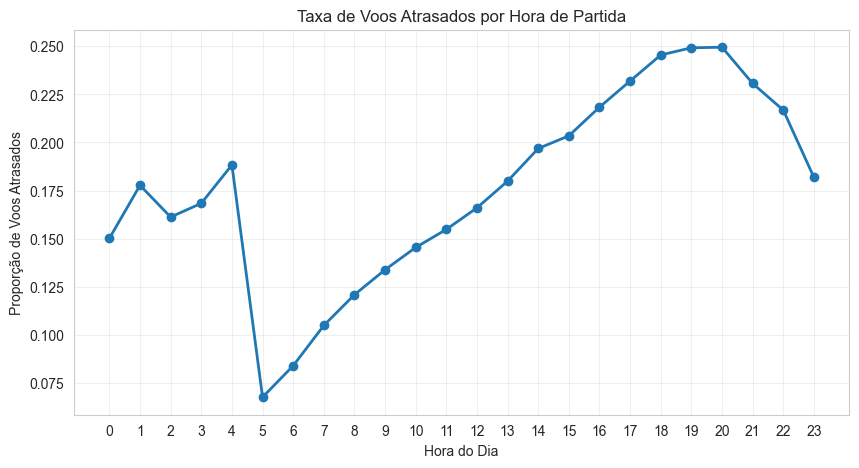

In [21]:
# Criar hora de partida
flights['DEPARTURE_HOUR'] = flights['SCHEDULED_DEPARTURE'] // 100

# Taxa de atraso por hora
delay_hour = (
    flights.groupby('DEPARTURE_HOUR')['Delayed']
    .mean()
)

plt.figure(figsize=(10,5))

delay_hour.plot(
    marker='o',
    linewidth=2
)

plt.title('Taxa de Voos Atrasados por Hora de Partida')
plt.xlabel('Hora do Dia')
plt.ylabel('Proporção de Voos Atrasados')
plt.grid(alpha=0.3)

plt.xticks(range(24))

plt.show()

Observa-se que a taxa de atrasos tende a aumentar ao longo do dia, atingindo os valores mais elevados entre o final da tarde e o início da noite. Este comportamento sugere um efeito acumulado dos atrasos operacionais ao longo do dia, enquanto as primeiras horas da manhã apresentam menor probabilidade de atraso.

#### Distribuição dos Atrasos na Chegada

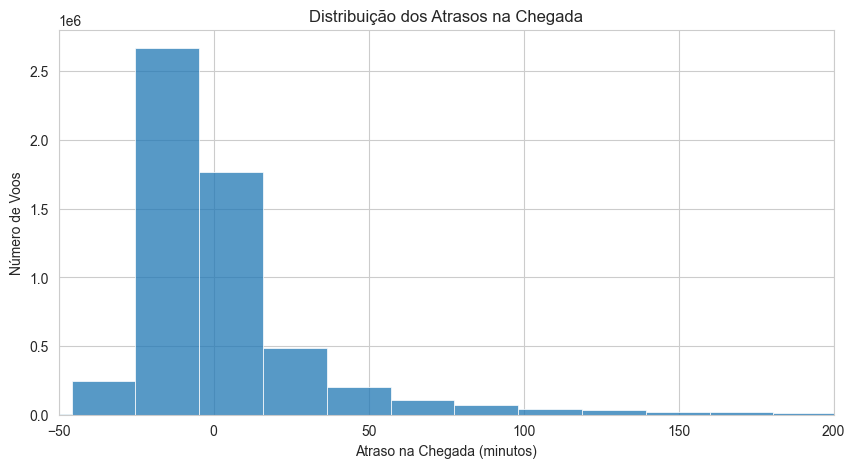

In [25]:
plt.figure(figsize=(10,5))
sns.histplot(flights['ARRIVAL_DELAY'], bins=100)

plt.xlim(-50,200)
plt.title('Distribuição dos Atrasos na Chegada')
plt.xlabel('Atraso na Chegada (minutos)')
plt.ylabel('Número de Voos')

plt.show()

A distribuição dos atrasos na chegada apresenta uma forte assimetria à direita. A maioria dos voos chega dentro do horário previsto ou com pequenos atrasos, enquanto um número reduzido de voos apresenta atrasos elevados. Este comportamento é comum em fenómenos operacionais, onde eventos excecionais podem provocar atrasos significativos.

#### Atraso Médio (minutos)

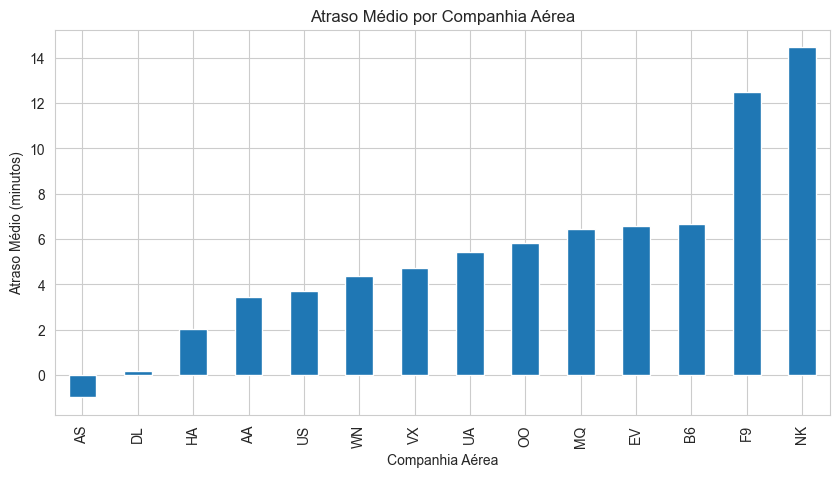

In [30]:
delay_airline = (
    flights.groupby('AIRLINE')['ARRIVAL_DELAY']
    .mean()
    .sort_values()
)

plt.figure(figsize=(10,5))
delay_airline.plot(kind='bar')

plt.title('Atraso Médio por Companhia Aérea')
plt.xlabel('Companhia Aérea')
plt.ylabel('Atraso Médio (minutos)')
plt.show()

A taxa de atrasos varia entre companhias aéreas, sugerindo diferenças na eficiência operacional, gestão de rotas ou capacidade de recuperação face a imprevistos. Algumas companhias apresentam uma proporção significativamente superior de voos atrasados, evidenciando possíveis desafios operacionais.

#### Percentagem de Voos Atrasados por Mês

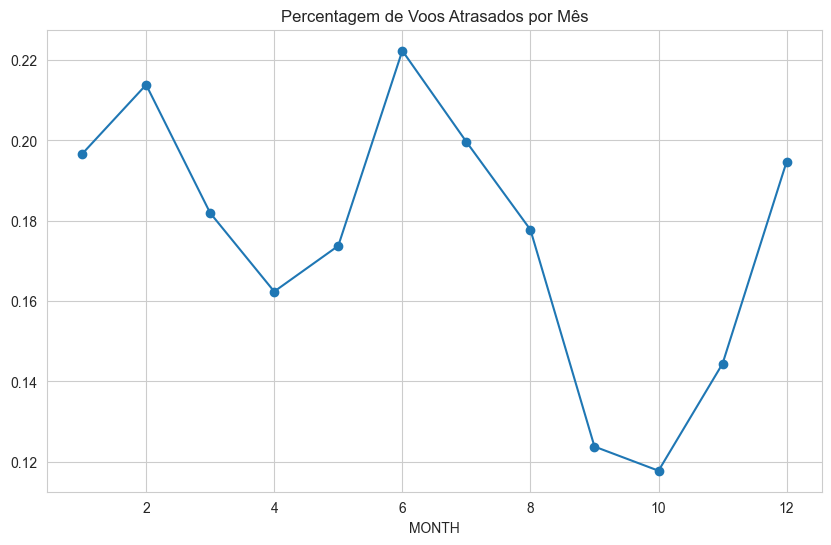

In [17]:
delay_month = flights.groupby('MONTH')['Delayed'].mean()

delay_month.plot(marker='o')
plt.title('Percentagem de Voos Atrasados por Mês')
plt.show()

A frequência dos atrasos varia ao longo do ano. Alguns meses apresentam maior incidência de atrasos, o que pode estar relacionado com períodos de maior tráfego aéreo, condições meteorológicas ou fatores sazonais.

#### Percentagem de Voos Atrasados por Dia da Semana

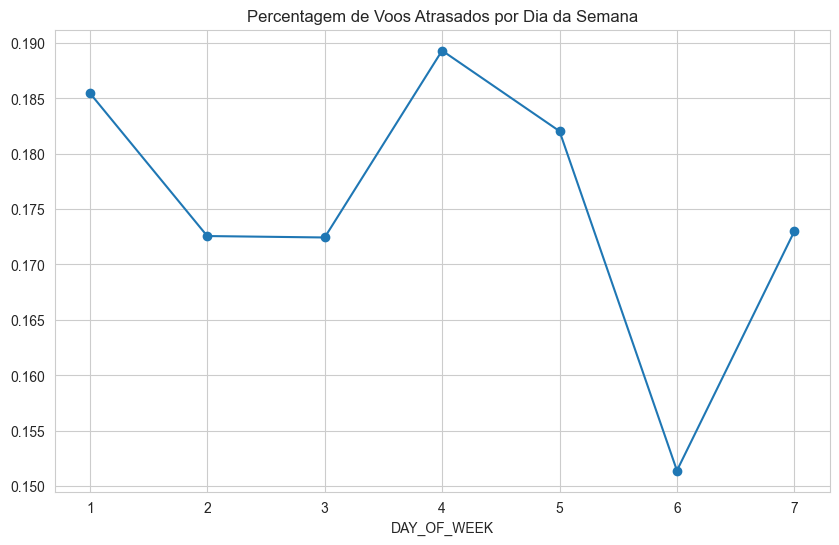

In [18]:
delay_week = flights.groupby('DAY_OF_WEEK')['Delayed'].mean()

delay_week.plot(marker='o')
plt.title('Percentagem de Voos Atrasados por Dia da Semana')
plt.show()

Este gráfico permite analisar a relação entre o dia da semana e a ocorrência de atrasos. Embora as diferenças não sejam muito acentuadas, alguns dias apresentam uma maior proporção de voos atrasados, podendo refletir padrões de procura e operação das companhias aéreas.

#### Distribuição da Variável Alvo

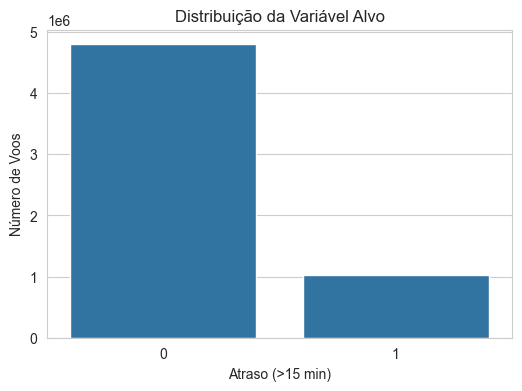

In [19]:
plt.figure(figsize=(6,4))
sns.countplot(x='Delayed', data=flights)

plt.title('Distribuição da Variável Alvo')
plt.xlabel('Atraso (>15 min)')
plt.ylabel('Número de Voos')

plt.show()

A variável alvo apresenta uma distribuição desequilibrada, verificando-se um maior número de voos sem atraso significativo em comparação com os voos atrasados. Esta característica deverá ser considerada na fase de modelação, uma vez que pode influenciar o desempenho dos algoritmos de classificação.

#### Top 10 Aeroportos com Maior Atraso Médio

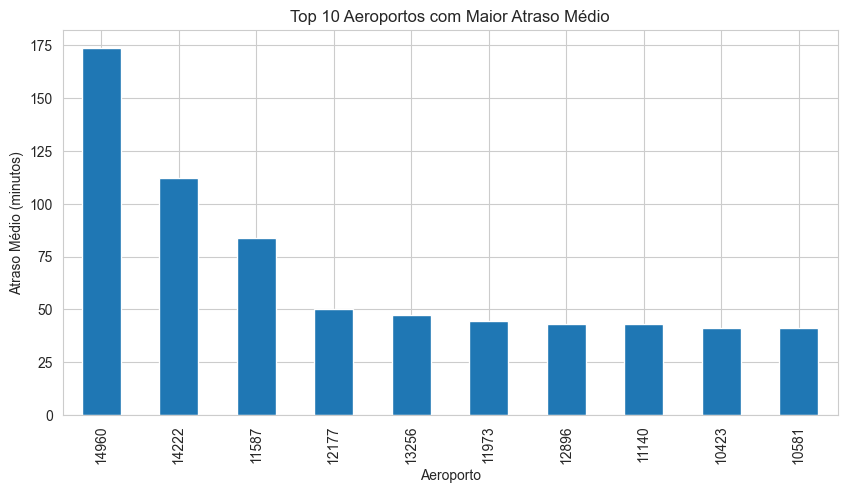

In [29]:
airport_delay = (
    flights.groupby('ORIGIN_AIRPORT')['ARRIVAL_DELAY']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))
airport_delay.plot(kind='bar')

plt.title('Top 10 Aeroportos com Maior Atraso Médio')
plt.xlabel('Aeroporto')
plt.ylabel('Atraso Médio (minutos)')
plt.show()

Alguns aeroportos apresentam taxas de atraso superiores às restantes infraestruturas analisadas. Este comportamento poderá estar relacionado com fatores como volume de tráfego aéreo, condições meteorológicas, limitações operacionais ou congestionamento das pistas.

#### Atraso Médio por Distância do Voo

C:\Users\Daniel\AppData\Local\Temp\ipykernel_16840\3699159492.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  flights.groupby('DISTANCE_GROUP')['ARRIVAL_DELAY']


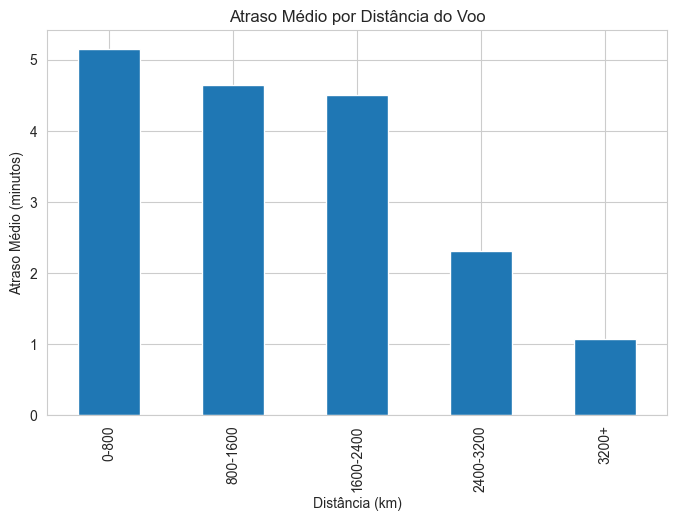

In [36]:
# Converter milhas para quilómetros
flights['DISTANCE_KM'] = flights['DISTANCE'] * 1.60934

flights['DISTANCE_GROUP'] = pd.cut(
    flights['DISTANCE_KM'],
    bins=[0, 800, 1600, 2400, 3200, 8000],
    labels=['0-800', '800-1600', '1600-2400', '2400-3200', '3200+']
)

delay_distance = (
    flights.groupby('DISTANCE_GROUP')['ARRIVAL_DELAY']
    .mean()
)

plt.figure(figsize=(8,5))

delay_distance.plot(kind='bar')

plt.title('Atraso Médio por Distância do Voo')
plt.xlabel('Distância (km)')
plt.ylabel('Atraso Médio (minutos)')

plt.show()

O gráfico apresenta o atraso médio em função da distância percorrida pelos voos. A análise permite verificar se a extensão da rota influencia a pontualidade das operações, identificando possíveis diferenças entre voos de curta, média e longa distância.

#### Taxa de Cancelamento por Mês

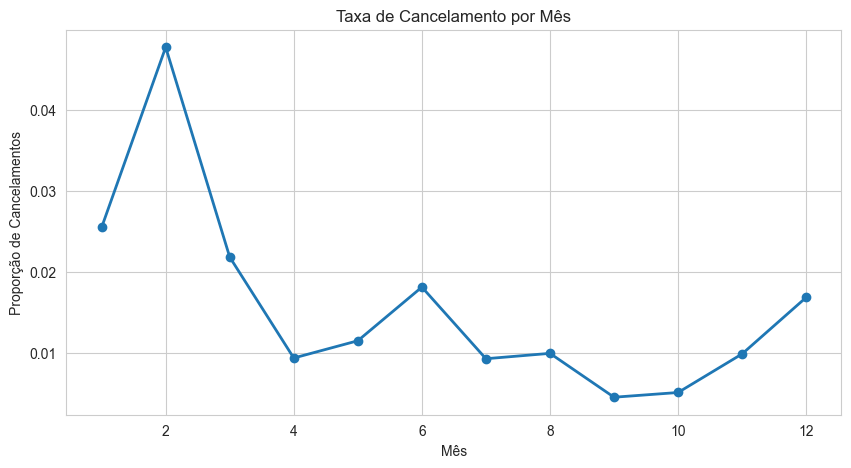

In [26]:
cancel_month = (
    flights.groupby('MONTH')['CANCELLED']
    .mean()
)

plt.figure(figsize=(10,5))

cancel_month.plot(
    marker='o',
    linewidth=2
)

plt.title('Taxa de Cancelamento por Mês')
plt.xlabel('Mês')
plt.ylabel('Proporção de Cancelamentos')
plt.show()

A taxa de cancelamento varia ao longo do ano, podendo refletir fatores sazonais como condições meteorológicas adversas ou períodos de maior procura.

#### Principais causas dos atrasos

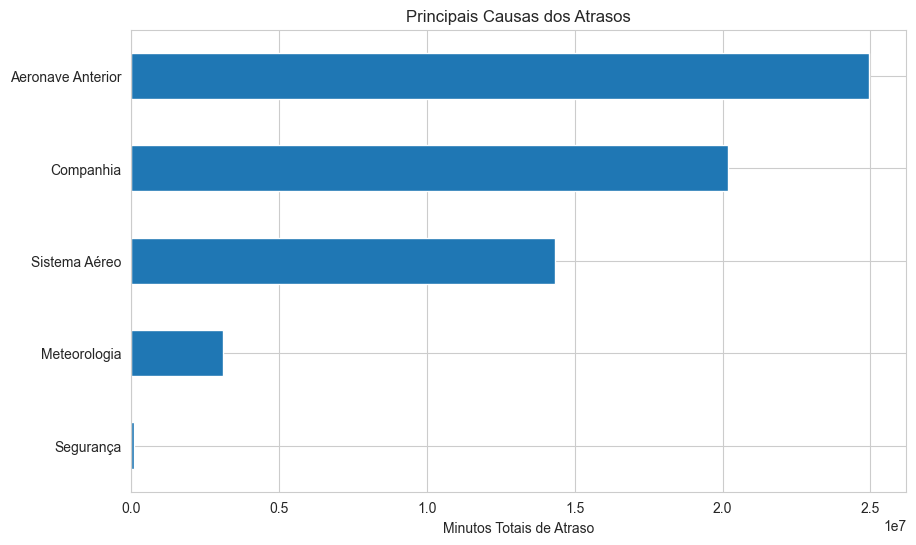

In [37]:
delay_causes = {
    'Sistema Aéreo': flights['AIR_SYSTEM_DELAY'].sum(),
    'Meteorologia': flights['WEATHER_DELAY'].sum(),
    'Companhia': flights['AIRLINE_DELAY'].sum(),
    'Segurança': flights['SECURITY_DELAY'].sum(),
    'Aeronave Anterior': flights['LATE_AIRCRAFT_DELAY'].sum()
}

pd.Series(delay_causes).sort_values().plot(kind='barh')

plt.title('Principais Causas dos Atrasos')
plt.xlabel('Minutos Totais de Atraso')
plt.show()

Os atrasos podem ter diferentes origens. A análise das causas permite identificar quais os fatores com maior impacto na pontualidade dos voos.

#### Motivos de Cancelamento dos Voos

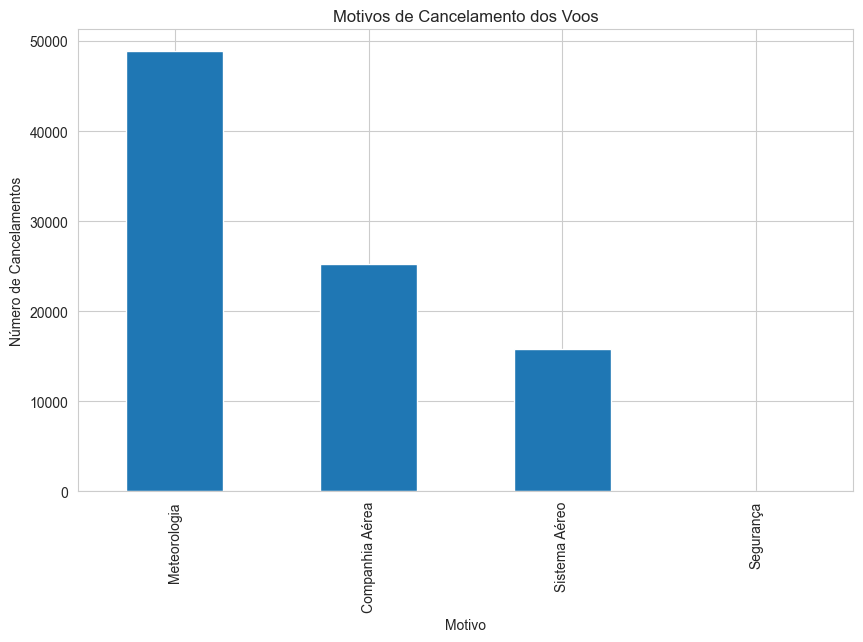

In [40]:
cancel_reason = flights['CANCELLATION_REASON'].replace({
    'A': 'Companhia Aérea',
    'B': 'Meteorologia',
    'C': 'Sistema Aéreo',
    'D': 'Segurança'
})

cancel_reason.value_counts().plot(kind='bar')

plt.title('Motivos de Cancelamento dos Voos')
plt.xlabel('Motivo')
plt.ylabel('Número de Cancelamentos')

plt.show()

A maioria dos cancelamentos está associada a condições meteorológicas adversas, seguindo-se fatores relacionados com as companhias aéreas e com o sistema nacional de aviação. Os cancelamentos por motivos de segurança representam apenas uma pequena fração do total observado.

#### Matriz de Correlação

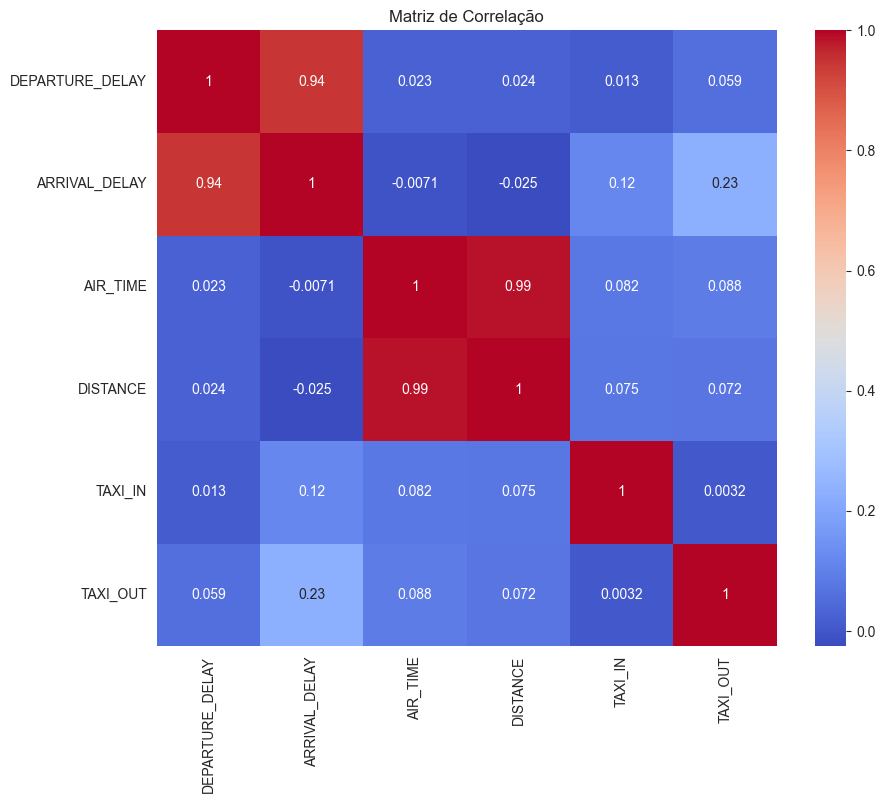

In [23]:
plt.figure(figsize=(10,8))

corr = flights[['DEPARTURE_DELAY',
                'ARRIVAL_DELAY',
                'AIR_TIME',
                'DISTANCE',
                'TAXI_IN',
                'TAXI_OUT']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Matriz de Correlação')
plt.show()

Verifica-se uma forte correlação positiva entre os atrasos na partida e na chegada, indicando que atrasos iniciais tendem a propagar-se ao longo do voo.

## Mapa dos Aeroportos com Maior Atraso Médio

Nesta análise é representada a distribuição geográfica dos aeroportos com maior atraso médio à chegada.

Cada ponto corresponde a um aeroporto, sendo o tamanho associado ao número de voos e a cor ao atraso médio observado.

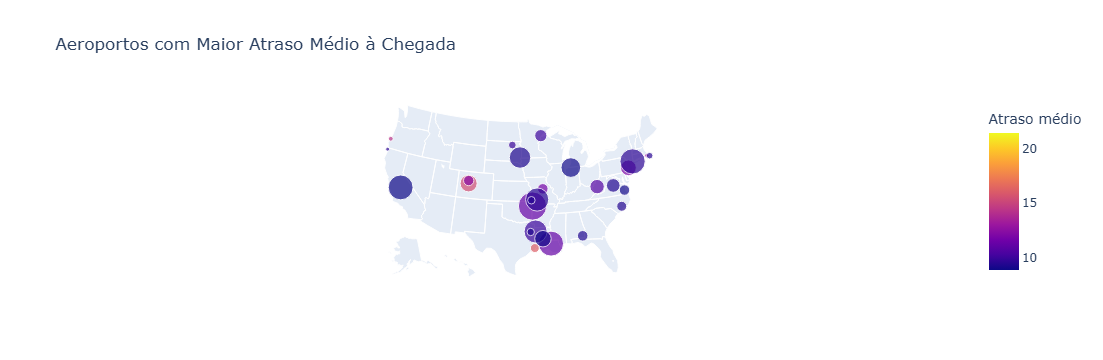

In [4]:
import plotly.express as px

# Calcular atraso médio e número de voos por aeroporto de origem
airport_delays = flights.groupby("ORIGIN_AIRPORT").agg(
    avg_arrival_delay=("ARRIVAL_DELAY", "mean"),
    num_flights=("ARRIVAL_DELAY", "count")
).reset_index()

# Manter apenas aeroportos com número mínimo de voos
airport_delays = airport_delays[airport_delays["num_flights"] >= 100]

# Juntar com dataset dos aeroportos
airport_map = airport_delays.merge(
    airports,
    left_on="ORIGIN_AIRPORT",
    right_on="IATA_CODE",
    how="inner"
)

# Selecionar os aeroportos com maior atraso médio
top_airport_map = airport_map.sort_values(
    by="avg_arrival_delay",
    ascending=False
).head(30)

fig = px.scatter_geo(
    top_airport_map,
    lat="LATITUDE",
    lon="LONGITUDE",
    scope="usa",
    size="num_flights",
    color="avg_arrival_delay",
    hover_name="AIRPORT",
    hover_data={
        "ORIGIN_AIRPORT": True,
        "avg_arrival_delay": ":.2f",
        "num_flights": True,
        "LATITUDE": False,
        "LONGITUDE": False
    },
    title="Aeroportos com Maior Atraso Médio à Chegada",
    labels={
        "avg_arrival_delay": "Atraso médio",
        "num_flights": "Nº de voos"
    }
)

fig.show()

O mapa permite identificar os aeroportos onde se registam maiores atrasos médios à chegada.

A dimensão dos pontos representa o volume de voos analisados, enquanto a cor indica a intensidade do atraso médio. Esta visualização facilita a identificação de padrões geográficos associados aos atrasos.

In [6]:
# Guardar dataset final tratado para usar no Notebook 2
flights.to_csv("flights_processed.csv", index=False)